In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import minimize


os.makedirs("outputs", exist_ok=True)
pd.options.display.float_format = "{:,.4f}".format


In [2]:
TOTAL_FUND      = 12_000_000        # USD, case decision date 31 Dec 2022
BASE_YEAR       = 2022
GOAL_YEAR       = 2030              # fund must be worth the real goal on 31 Dec 2030
REAL_GOAL_USD   = 8_000_000         # purchasing power of USD 8M in Dec 2022 (from the case)
OLD_LIABILITIES = {2024: 2_400_000, 2027: 3_600_000}
NEW_LIABILITIES = {2024: 2_400_000, 2025: 1_200_000, 2027: 2_400_000}


# ---- ASSUMPTIONS NOT GIVEN IN THE CASE (state and defend them in the memo) ----
INFLATION     = 0.025   # 2.5% annual inflation, as fixed in the 22 Oct Initial Decision Record
CASH_REINVEST = 0.0     # surplus coupons kept as cash with no interest (as in the 22 Oct record)
RF_ANNUAL       = 0.03
GROWTH_TICKERS  = ["AAPL", "MSFT", "TSLA", "QQQ"]   # same stock set for BOTH methods
MARKET_TICKER   = "SPY"             # market index for the single-index model


In [3]:
bonds = pd.read_csv("data/raw/case_bonds.csv")
display(bonds)

def match_bonds(liabilities):
    holdings = {}
    for year in sorted(liabilities, reverse=True):
        m = year - BASE_YEAR
        b = bonds.loc[bonds["Maturity_Years"] == m].iloc[0]
        coupons_in = sum(h["face"] * h["coupon"] for h in holdings.values() if h["maturity"] > m)
        face = (liabilities[year] - coupons_in) / (1 + b["Annual_Coupon_Rate"])
        holdings[b["Bond"]] = dict(year=year, maturity=m, coupon=b["Annual_Coupon_Rate"], face=face,
                                   cost=face / b["Face_Value"] * b["Price"])
    alloc = pd.DataFrame(holdings).T[["year", "maturity", "coupon", "face", "cost"]].astype(float)

    years = range(BASE_YEAR + 1, max(liabilities) + 1)
    inflow = {y: 0.0 for y in years}
    for h in holdings.values():
        for y in years:
            t = y - BASE_YEAR
            if t <= h["maturity"]:
                inflow[y] += h["face"] * h["coupon"] + (h["face"] if t == h["maturity"] else 0.0)
    cf = pd.DataFrame({"Bond inflow": inflow, "Liability": {y: float(liabilities.get(y, 0.0)) for y in years}})
    cf["Surplus"] = cf["Bond inflow"] - cf["Liability"]
    assert cf["Surplus"].min() > -1.0, "A liability is not fully funded!"
    return alloc, cf.clip(lower=0.0)

alloc_old, cf_old = match_bonds(OLD_LIABILITIES)
alloc_new, cf_new = match_bonds(NEW_LIABILITIES)
old_bond_cost, new_bond_cost = alloc_old["cost"].sum(), alloc_new["cost"].sum()

print("OLD mandate"); display(alloc_old); display(cf_old)
print("NEW (revised) mandate"); display(alloc_new); display(cf_new)

assert abs(old_bond_cost - 5_532_142.27) < 1.0, "Old cost does not match the initial decision record"
assert abs(new_bond_cost - 5_465_096.48) < 1.0, "New cost does not match bond_analysis_revised.ipynb"
print(f"Bond cost  old = ${old_bond_cost:,.2f} | new = ${new_bond_cost:,.2f}  (matches Linh's notebook)")


,Bond,Maturity_Years,Annual_Coupon_Rate,Price,Face_Value
0,Alpha,1,0.0000,958.7700,1000
1,Beta,2,0.0000,922.7800,1000
2,Gamma,3,0.0400,"1,002.4900",1000
3,Delta,5,0.0350,986.0700,1000
4,Epsilon,8,0.0450,"1,040.7100",1000


OLD mandate


,year,maturity,coupon,face,cost
Delta,"2,027.0000",5.0000,0.0350,"3,478,260.8696","3,429,808.6957"
Beta,"2,024.0000",2.0000,0.0000,"2,278,260.8696","2,102,333.5652"


,Bond inflow,Liability,Surplus
2023,"121,739.1304",0.0000,"121,739.1304"
2024,"2,400,000.0000","2,400,000.0000",0.0000
2025,"121,739.1304",0.0000,"121,739.1304"
2026,"121,739.1304",0.0000,"121,739.1304"
2027,"3,600,000.0000","3,600,000.0000",0.0000


NEW (revised) mandate


,year,maturity,coupon,face,cost
Delta,"2,027.0000",5.0000,0.0350,"2,318,840.5797","2,286,539.1304"
Gamma,"2,025.0000",3.0000,0.0400,"1,075,808.2497","1,078,487.0123"
Beta,"2,024.0000",2.0000,0.0000,"2,275,808.2497","2,100,070.3367"


,Bond inflow,Liability,Surplus
2023,"124,191.7503",0.0000,"124,191.7503"
2024,"2,400,000.0000","2,400,000.0000",0.0000
2025,"1,200,000.0000","1,200,000.0000",0.0000
2026,"81,159.4203",0.0000,"81,159.4203"
2027,"2,400,000.0000","2,400,000.0000",0.0000


Bond cost  old = $5,532,142.26 | new = $5,465,096.48  (matches Linh's notebook)


In [4]:
H = GOAL_YEAR - BASE_YEAR

def required_return(bond_cost, cf, inflation=INFLATION):
    equity     = TOTAL_FUND - bond_cost
    target     = REAL_GOAL_USD * (1 + inflation) ** H
    fv_surplus = sum(s * (1 + CASH_REINVEST) ** (GOAL_YEAR - y) for y, s in cf["Surplus"].items())
    R = ((target - fv_surplus) / equity) ** (1 / H) - 1
    return equity, target, fv_surplus, R

rows = {}
for label, cost, cf in [("Old mandate", old_bond_cost, cf_old), ("New mandate", new_bond_cost, cf_new)]:
    eq, tgt, fv, R = required_return(cost, cf)
    rows[label] = {"Bond cost": cost, "Capital for growth (E)": eq, "Surplus bond cash (undiscounted)": cf["Surplus"].sum(),
                   "FV of surplus cash in 2030": fv, "Nominal target 2030 (T)": tgt, "Required return (p.a.)": R}
summary = pd.DataFrame(rows)
display(summary)

equity_old = summary.loc["Capital for growth (E)", "Old mandate"]
equity_new = summary.loc["Capital for growth (E)", "New mandate"]
REQUIRED_RETURN_OLD = summary.loc["Required return (p.a.)", "Old mandate"]
REQUIRED_RETURN_NEW = summary.loc["Required return (p.a.)", "New mandate"]
print(f"Revised mandate: growth capital {equity_new - equity_old:+,.0f} USD, "
      f"surplus bond cash {cf_new['Surplus'].sum() - cf_old['Surplus'].sum():+,.0f} USD, "
      f"required return {REQUIRED_RETURN_OLD:.2%} -> {REQUIRED_RETURN_NEW:.2%}")

# sensitivity to the inflation assumption (not given in the case)
sens = pd.DataFrame({f"inflation {i:.1%}": {"Old": required_return(old_bond_cost, cf_old, i)[3],
                                            "New": required_return(new_bond_cost, cf_new, i)[3]}
                     for i in [0.015, 0.02, 0.025, 0.03, 0.035]})
display(sens)

pd.DataFrame([{"equity_old": equity_old, "equity_new": equity_new, "required_return_old": REQUIRED_RETURN_OLD,

               "required_return_new": REQUIRED_RETURN_NEW, "new_bond_cost": new_bond_cost, "inflation": INFLATION,
               "cash_reinvest": CASH_REINVEST}]).to_csv("outputs/required_return.csv", index=False)
sens.to_csv("outputs/required_return_sensitivity.csv")


,Old mandate,New mandate
Bond cost,"5,532,142.2609","5,465,096.4794"
Capital for growth (E),"6,467,857.7391","6,534,903.5206"
Surplus bond cash (undiscounted),"365,217.3913","205,351.1706"
FV of surplus cash in 2030,"365,217.3913","205,351.1706"
Nominal target 2030 (T),"9,747,223.1801","9,747,223.1801"
Required return (p.a.),0.0476,0.0485


Revised mandate: growth capital +67,046 USD, surplus bond cash -159,866 USD, required return 4.76% -> 4.85%


,inflation 1.5%,inflation 2.0%,inflation 2.5%,inflation 3.0%,inflation 3.5%
Old,0.0370,0.0423,0.0476,0.0529,0.0582
New,0.0380,0.0432,0.0485,0.0537,0.0589


In [5]:
returns_path = "data/processed/stock_monthly_returns.csv"
price_path   = "data/raw/stock_monthly_prices.csv"
if os.path.exists(returns_path):
    returns_df = pd.read_csv(returns_path, index_col=0, parse_dates=True)
else:
    returns_df = pd.read_csv(price_path, index_col=0, parse_dates=True).pct_change().dropna()

R   = returns_df[GROWTH_TICKERS]
Rm  = returns_df[MARKET_TICKER]
n   = len(GROWTH_TICKERS)
print(f"Sample: {returns_df.index.min():%Y-%m} to {returns_df.index.max():%Y-%m}  ({len(R)} monthly observations)")

mu = R.mean() * 12                       # expected annual returns
cov_sample = R.cov() * 12                # sample covariance (annualised)

# Single-index model: R_i = alpha_i + beta_i * R_m + e_i
X = sm.add_constant(Rm)
rows = {}
for t in GROWTH_TICKERS:
    fit = sm.OLS(R[t], X).fit()
    rows[t] = {"alpha_monthly": fit.params.iloc[0], "beta": fit.params.iloc[1],
               "resid_var_annual": fit.resid.var() * 12, "R2": fit.rsquared}
sim_params = pd.DataFrame(rows).T
display(sim_params)

var_m = Rm.var() * 12
beta  = sim_params["beta"].values
cov_sim = np.outer(beta, beta) * var_m
cov_sim[np.diag_indices(n)] += sim_params["resid_var_annual"].values
cov_sim = pd.DataFrame(cov_sim, index=GROWTH_TICKERS, columns=GROWTH_TICKERS)

print("Expected annual returns:"); display(mu.to_frame("mu"))

print("Sample covariance (annual):"); display(cov_sample)
print("Single-index covariance (annual):"); display(cov_sim)


Sample: 2015-02 to 2022-12  (95 monthly observations)


,alpha_monthly,beta,resid_var_annual,R2
AAPL,0.0084,1.2712,0.0445,0.4798
MSFT,0.0129,0.9948,0.0231,0.5213
TSLA,0.0209,1.7992,0.3138,0.2076
QQQ,0.0019,1.1147,0.0051,0.8608


Expected annual returns:


,mu
AAPL,0.2450
MSFT,0.2678
TSLA,0.4559
QQQ,0.1494


Sample covariance (annual):


,AAPL,MSFT,TSLA,QQQ
AAPL,0.0855,0.0397,0.0975,0.0450
MSFT,0.0397,0.0482,0.0589,0.0347
TSLA,0.0975,0.0589,0.3960,0.0661
QQQ,0.0450,0.0347,0.0661,0.0367


Single-index covariance (annual):


,AAPL,MSFT,TSLA,QQQ
AAPL,0.0855,0.0321,0.0581,0.0360
MSFT,0.0321,0.0482,0.0455,0.0282
TSLA,0.0581,0.0455,0.3960,0.0509
QQQ,0.0360,0.0282,0.0509,0.0367


In [6]:
def _solve(objective, extra=()):
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1.0}, *extra]
    res = minimize(objective, np.full(n, 1 / n), method="SLSQP", bounds=[(0, 1)] * n,
                   constraints=cons, options={"ftol": 1e-12, "maxiter": 1000})
    return res.x

def stats_of(w, cov):
    ret = float(w @ mu.values)
    vol = float(np.sqrt(w @ cov.values @ w))
    return ret, vol, (ret - RF_ANNUAL) / vol

def min_variance(cov, target=None):
    extra = [] if target is None else [{"type": "eq", "fun": lambda w: w @ mu.values - target}]
    return _solve(lambda w: w @ cov.values @ w, extra)

def max_sharpe(cov):
    return _solve(lambda w: -(w @ mu.values - RF_ANNUAL) / np.sqrt(w @ cov.values @ w))

def frontier(cov, points=60):
    w_gmv = min_variance(cov)
    lo, hi = w_gmv @ mu.values, mu.max() * 0.999
    pts = []
    for tgt in np.linspace(lo, hi, points):
        w = min_variance(cov, tgt)
        r, v, _ = stats_of(w, cov)
        pts.append((v, r))
    return np.array(pts)

models = {"Sample covariance": cov_sample, "Single-index model": cov_sim}
results, frontiers, weights = [], {}, {}

for name, cov in models.items():

    w_gmv = min_variance(cov)
    w_tan = max_sharpe(cov)
    feasible = REQUIRED_RETURN_NEW <= mu.max()
    tgt = min(max(REQUIRED_RETURN_NEW, w_gmv @ mu.values), mu.max() * 0.999)
    w_req = min_variance(cov, tgt)
    if REQUIRED_RETURN_NEW < w_gmv @ mu.values:
        print(f"[{name}] required return {REQUIRED_RETURN_NEW:.2%} is below the min-variance return "
              f"{w_gmv @ mu.values:.2%} -> the min-variance portfolio already meets it")
    for label, w in [("Min-variance", w_gmv), ("Max-Sharpe (tangency)", w_tan),
                     (f"Required return ({REQUIRED_RETURN_NEW:.2%})", w_req)]:
        r, v, s = stats_of(w, cov)
        results.append({"Model": name, "Portfolio": label, "Return": r, "Risk (stdev)": v, "Sharpe": s,
                        **{t: wi for t, wi in zip(GROWTH_TICKERS, w)}})
    frontiers[name] = frontier(cov)
    weights[name] = dict(gmv=w_gmv, tan=w_tan, req=w_req)
    if not feasible:
        print(f"[{name}] required return {REQUIRED_RETURN_NEW:.2%} > best single asset {mu.max():.2%} -> not reachable long-only")

results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.to_csv("outputs/portfolio_optimization_results.csv", index=False)


[Sample covariance] required return 4.85% is below the min-variance return 16.45% -> the min-variance portfolio already meets it
[Single-index model] required return 4.85% is below the min-variance return 18.46% -> the min-variance portfolio already meets it


,Model,Portfolio,Return,Risk (stdev),Sharpe,AAPL,MSFT,TSLA,QQQ
0,Sample covariance,Min-variance,0.1645,0.1908,0.7050,0.0000,0.1280,0.0000,0.8720
1,Sample covariance,Max-Sharpe (tangency),0.2841,0.2291,1.1090,0.0000,0.9136,0.0864,0.0000
2,Sample covariance,Required return (4.85%),0.1645,0.1908,0.7050,0.0000,0.1280,0.0000,0.8720
3,Single-index model,Min-variance,0.1846,0.1848,0.8369,0.0000,0.2976,0.0000,0.7024
4,Single-index model,Max-Sharpe (tangency),0.2838,0.2213,1.1467,0.1267,0.7731,0.1002,0.0000
5,Single-index model,Required return (4.85%),0.1846,0.1848,0.8369,0.0000,0.2976,0.0000,0.7024


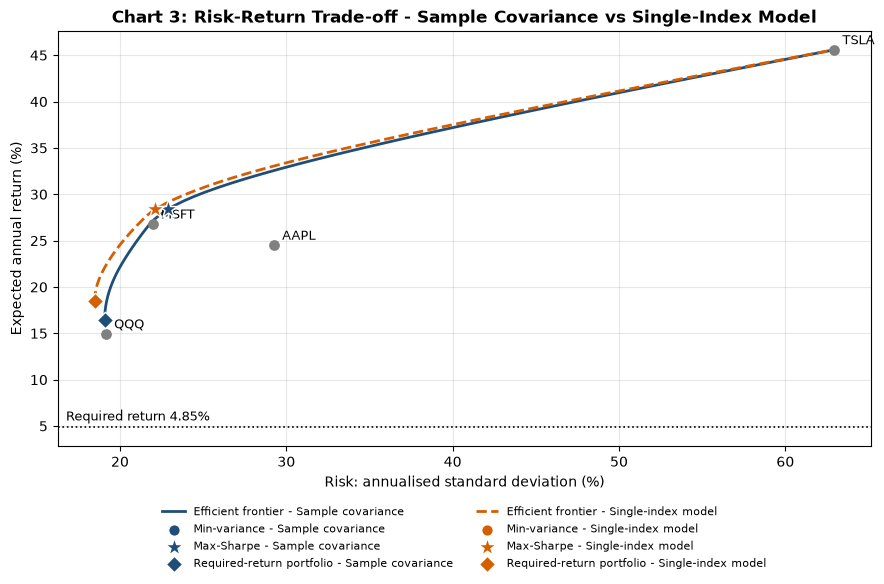

In [7]:
colors = {"Sample covariance": "#1f4e79", "Single-index model": "#d55e00"}
styles = {"Sample covariance": "-", "Single-index model": "--"}

fig, ax = plt.subplots(figsize=(9, 6))
for name, cov in models.items():
    f = frontiers[name]
    ax.plot(f[:, 0] * 100, f[:, 1] * 100, styles[name], color=colors[name], lw=2, label=f"Efficient frontier - {name}")
    for key, marker, lab in [("gmv", "o", "Min-variance"), ("tan", "*", "Max-Sharpe"), ("req", "D", "Required-return portfolio")]:
        r, v, _ = stats_of(weights[name][key], cov)
        ax.scatter(v * 100, r * 100, marker=marker, s=190 if marker == "*" else 70, color=colors[name],
                   edgecolor="white", zorder=5, label=f"{lab} - {name}")

for t in GROWTH_TICKERS:
    ax.scatter(np.sqrt(cov_sample.loc[t, t]) * 100, mu[t] * 100, color="grey", s=45, zorder=4)
    ax.annotate(t, (np.sqrt(cov_sample.loc[t, t]) * 100, mu[t] * 100), xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.axhline(REQUIRED_RETURN_NEW * 100, color="black", ls=":", lw=1.2)
ax.annotate(f"Required return {REQUIRED_RETURN_NEW:.2%}", (ax.get_xlim()[0], REQUIRED_RETURN_NEW * 100),
            xytext=(6, 5), textcoords="offset points", fontsize=9)

ax.set_title("Chart 3: Risk-Return Trade-off - Sample Covariance vs Single-Index Model", fontweight="bold")
ax.set_xlabel("Risk: annualised standard deviation (%)")
ax.set_ylabel("Expected annual return (%)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig("outputs/chart3_risk_return.png", dpi=200)
plt.show()
